In [16]:

from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image, UnidentifiedImageError
from sklearn.model_selection import train_test_split

print("Toutes les bibliothèques ont été importées avec succès !")

Toutes les bibliothèques ont été importées avec succès !


In [17]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

DATASET_DIR = PROJECT_ROOT / "Data" / "classification" / "raw"
IMAGE_EXTENSIONS = {".jpeg", ".jpg", ".bmp", ".png"}

print("Project root :", PROJECT_ROOT)
print("Dataset path :", DATASET_DIR)
print("Dataset exists :", DATASET_DIR.exists())


Project root : c:\Users\ajbba\Desktop\YOUCODE-IA\Diagnostic_tumeurs
Dataset path : c:\Users\ajbba\Desktop\YOUCODE-IA\Diagnostic_tumeurs\Data\classification\raw
Dataset exists : True


In [18]:
class_directories = sorted(
    path for path in DATASET_DIR.iterdir()
    if path.is_dir()
)

image_records = []
ignored_files = []

for class_directory in class_directories:

    for file_path in class_directory.rglob("*"):

        if not file_path.is_file():
            continue

        if file_path.suffix.lower() not in IMAGE_EXTENSIONS:
            ignored_files.append(file_path)
            continue

        image_records.append({
            "image_path": file_path,
            "class": class_directory.name
        })

print("Classes détectées :")

for class_directory in class_directories:
    print("-", class_directory.name)

print("\nNombre de fichiers avec une extension autorisée :", len(image_records))
print("Nombre de fichiers ignorés à cause de leur extension :", len(ignored_files))

Classes détectées :
- glioma
- meningioma
- notumor
- pituitary

Nombre de fichiers avec une extension autorisée : 7023
Nombre de fichiers ignorés à cause de leur extension : 0


In [19]:
valid_records = []
corrupted_files = []

for record in image_records:

    image_path = record["image_path"]

    try:
        with Image.open(image_path) as image:
            image.verify()

        valid_records.append(record)

    except (UnidentifiedImageError, OSError, ValueError) as error:
        corrupted_files.append({
            "image_path": image_path,
            "error": str(error)
        })

images_df = pd.DataFrame(valid_records)

print("Nombre d'images valides :", len(valid_records))
print("Nombre de fichiers illisibles :", len(corrupted_files))

if corrupted_files:
    print("\nExemples de fichiers illisibles :")
    display(pd.DataFrame(corrupted_files).head())

Nombre d'images valides : 7023
Nombre de fichiers illisibles : 0


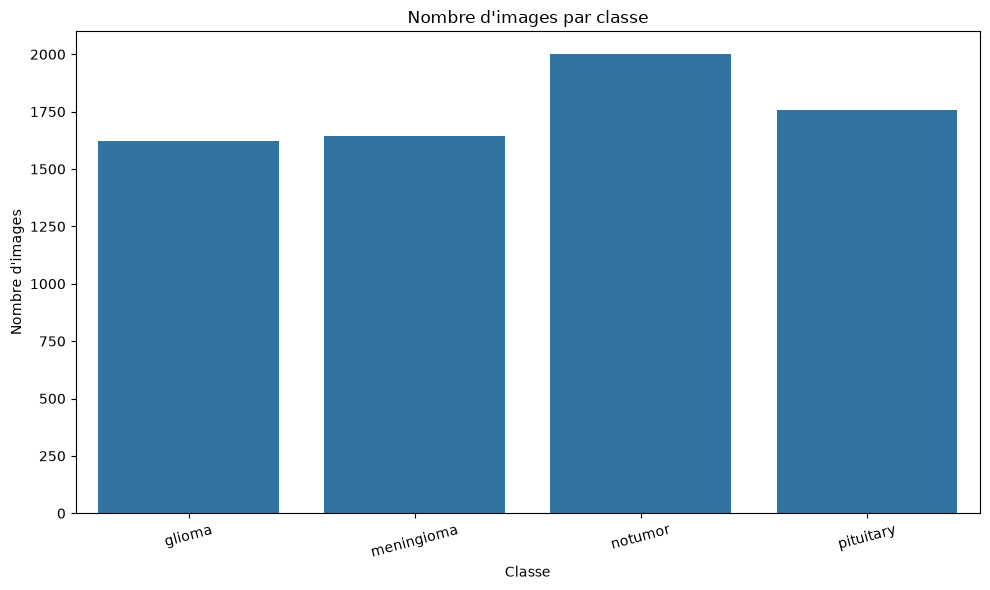

In [20]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=images_df,
    x="class",
    order=sorted(images_df["class"].unique())
)

plt.title("Nombre d'images par classe")
plt.xlabel("Classe")
plt.ylabel("Nombre d'images")

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

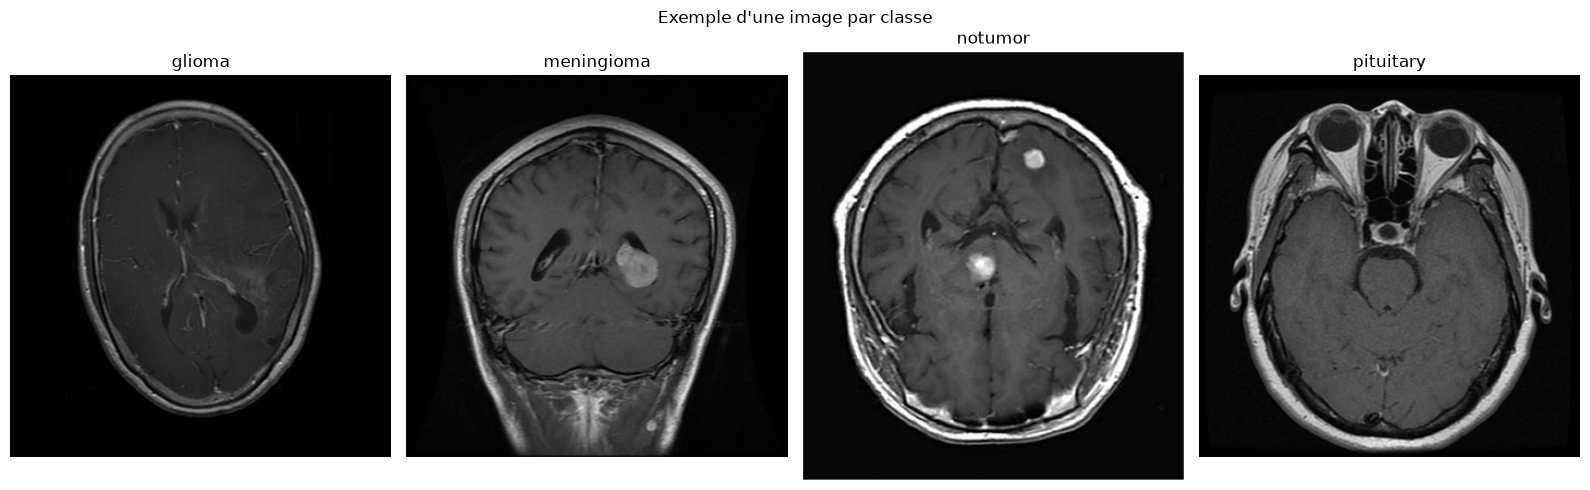

In [21]:
classes = sorted(images_df["class"].unique())

fig, axes = plt.subplots(
    1,
    len(classes),
    figsize=(16, 5)
)

for ax, class_name in zip(axes, classes):

    class_images = images_df[
        images_df["class"] == class_name
    ]

    sample = class_images.sample(
        n=1,
        random_state=42
    ).iloc[0]

    with Image.open(sample["image_path"]) as image:
        ax.imshow(image.convert("RGB"))

    ax.set_title(class_name)
    ax.axis("off")

plt.suptitle("Exemple d'une image par classe")
plt.tight_layout()
plt.show()

In [22]:
train_df, temp_df = train_test_split(
    images_df,
    test_size=0.30,
    random_state=42,
    stratify=images_df["class"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["class"]
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Répartition du dataset :")
print(f"Train      : {len(train_df)} images")
print(f"Validation : {len(val_df)} images")
print(f"Test       : {len(test_df)} images")

print("\nPourcentages obtenus :")
print(f"Train      : {len(train_df) / len(images_df) * 100:.2f}%")
print(f"Validation : {len(val_df) / len(images_df) * 100:.2f}%")
print(f"Test       : {len(test_df) / len(images_df) * 100:.2f}%")

Répartition du dataset :
Train      : 4916 images
Validation : 1053 images
Test       : 1054 images

Pourcentages obtenus :
Train      : 70.00%
Validation : 14.99%
Test       : 15.01%


In [23]:
split_counts = pd.DataFrame({
    "Ensemble": ["Train", "Validation", "Test"],
    "Nombre_images": [
        len(train_df),
        len(val_df),
        len(test_df)
    ]
})

display(split_counts)

print("Total des images réparties :", split_counts["Nombre_images"].sum())
print("Total des images valides    :", len(images_df))

assert split_counts["Nombre_images"].sum() == len(images_df)

print("\nVérification réussie : toutes les images valides sont réparties.")

,Ensemble,Nombre_images
0,Train,4916
1,Validation,1053
2,Test,1054


Total des images réparties : 7023
Total des images valides    : 7023

Vérification réussie : toutes les images valides sont réparties.


In [24]:
distribution = pd.concat(
    [
        train_df.assign(Ensemble="Train"),
        val_df.assign(Ensemble="Validation"),
        test_df.assign(Ensemble="Test")
    ],
    ignore_index=True
)

distribution_table = pd.crosstab(
    distribution["class"],
    distribution["Ensemble"]
)

display(distribution_table)

Ensemble,Test,Train,Validation
class,,,
glioma,243,1135,243
meningioma,247,1151,247
notumor,300,1400,300
pituitary,264,1230,263


In [25]:
#biblioteques pour 
import numpy as np
import random
from PIL import Image, ImageFilter, ImageOps
from pathlib import Path
import pandas as pd

In [26]:
def apply_augmentation(image, method):

    if method == "blur":
        return image.filter(
            ImageFilter.GaussianBlur(radius=0.5)
        )

    elif method == "noise":
        image_array = np.array(image).astype(np.float32)

        noise = np.random.normal(
            loc=0,
            scale=8,
            size=image_array.shape
        )

        noisy_array = np.clip(
            image_array + noise,
            0,
            255
        ).astype(np.uint8)

        return Image.fromarray(noisy_array)

    elif method == "flip":
        return ImageOps.mirror(image)

    else:
        raise ValueError(f"Méthode inconnue : {method}")

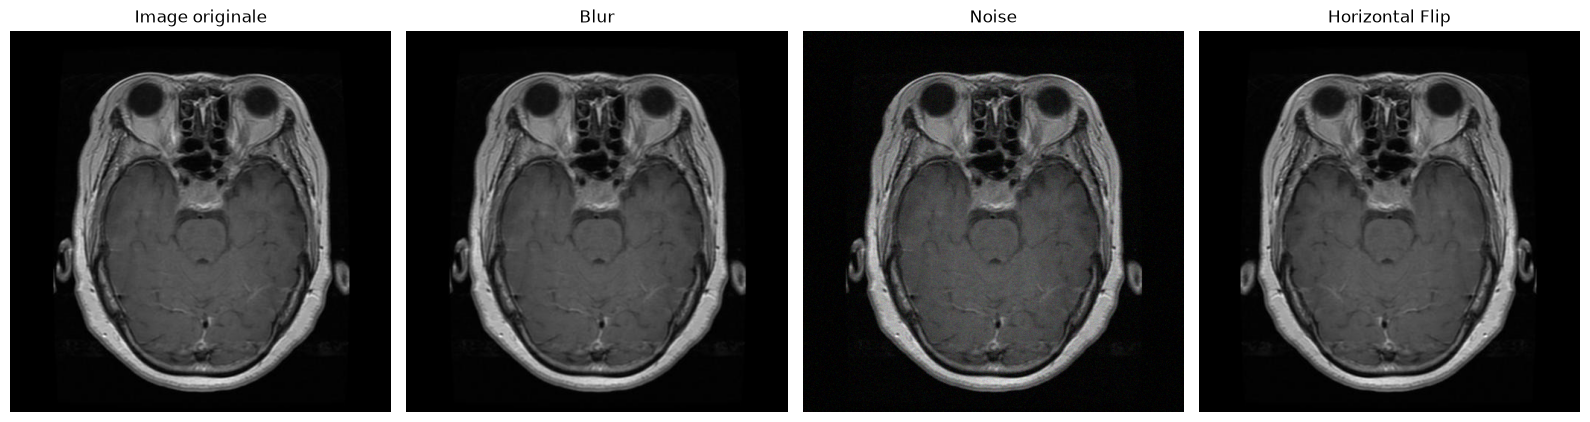

In [27]:
# Sélectionner une image de Train
sample = train_df.sample(n=1, random_state=42).iloc[0]

# Ouvrir l'image originale
with Image.open(sample["image_path"]) as original_image:
    original_image = original_image.convert("RGB")

    # Appliquer les trois transformations
    blur_image = apply_augmentation(original_image, "blur")
    noise_image = apply_augmentation(original_image, "noise")
    flip_image = apply_augmentation(original_image, "flip")

# Afficher les quatre images
fig, axes = plt.subplots(1, 4, figsize=(16, 5))

images = [
    original_image,
    blur_image,
    noise_image,
    flip_image
]

titles = [
    "Image originale",
    "Blur",
    "Noise",
    "Horizontal Flip"
]

for ax, image, title in zip(axes, images, titles):
    ax.imshow(image)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [28]:
train_counts = train_df["class"].value_counts()

display(train_counts)
target_count = train_counts.max()

print("Nombre cible par classe :", target_count)
# Fixer les graines aléatoires
random.seed(42)
np.random.seed(42)

# Déterminer le dossier de sortie
AUGMENTED_DIR = (
    PROJECT_ROOT
    / "Data"
    / "classification"
    / "processed"
    / "train_augmented_v1"
)

AUGMENTED_DIR.mkdir(parents=True, exist_ok=True)

# Définir les techniques disponibles
augmentation_methods = ["blur", "noise", "flip"]

# Préparer une liste pour les nouvelles images
augmented_records = []

# Parcourir chaque classe de Train
for class_name in sorted(train_df["class"].unique()):

    # Récupérer les images de la classe actuelle
    class_images = train_df[
        train_df["class"] == class_name
    ]

    # Calculer le nombre d'images à ajouter
    current_count = len(class_images)
    missing_count = target_count - current_count

    print(
        f"{class_name} : {current_count} images originales, "
        f"{missing_count} images à générer"
    )

    # Créer un dossier pour cette classe
    class_output_dir = AUGMENTED_DIR / class_name
    class_output_dir.mkdir(parents=True, exist_ok=True)

    # Générer les images supplémentaires
    for index in range(missing_count):

        # Sélectionner une image originale
        sample = class_images.sample(
            n=1,
            random_state=42 + index
        ).iloc[0]

        # Choisir une transformation
        method = random.choice(augmentation_methods)

        # Ouvrir et transformer l'image
        with Image.open(sample["image_path"]) as source_image:
            image = source_image.convert("RGB")
            augmented_image = apply_augmentation(image, method)

        # Définir le chemin de sortie
        output_path = (
            class_output_dir
            / f"aug_{index:05d}_{method}.png"
        )

        # Enregistrer l'image augmentée
        augmented_image.save(output_path)

        # Enregistrer les informations de l'image
        augmented_records.append({
            "image_path": output_path,
            "class": class_name,
            "augmentation": method
        })

print("\nNombre d'images augmentées :", len(augmented_records))
print("Dossier de sortie :", AUGMENTED_DIR)

class
notumor       1400
pituitary     1230
meningioma    1151
glioma        1135
Name: count, dtype: int64

Nombre cible par classe : 1400
glioma : 1135 images originales, 265 images à générer
meningioma : 1151 images originales, 249 images à générer
notumor : 1400 images originales, 0 images à générer
pituitary : 1230 images originales, 170 images à générer

Nombre d'images augmentées : 684
Dossier de sortie : c:\Users\ajbba\Desktop\YOUCODE-IA\Diagnostic_tumeurs\Data\classification\processed\train_augmented_v1


In [29]:
# Convertir les informations des nouvelles images en DataFrame
augmented_df = pd.DataFrame(augmented_records)

# Combiner les images originales et augmentées
train_final_df = pd.concat(
    [
        train_df[["image_path", "class"]],
        augmented_df[["image_path", "class"]]
    ],
    ignore_index=True
)

# Compter les images par classe
final_train_counts = train_final_df["class"].value_counts()

print("Images originales :", len(train_df))
print("Images augmentées :", len(augmented_df))
print("Total pour l'entraînement :", len(train_final_df))

print("\nRépartition finale par classe :")
display(final_train_counts)

Images originales : 4916
Images augmentées : 684
Total pour l'entraînement : 5600

Répartition finale par classe :


class
glioma        1400
notumor       1400
meningioma    1400
pituitary     1400
Name: count, dtype: int64

In [30]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from tensorflow.keras.utils import load_img, img_to_array

In [31]:
# Sélectionner une image dans le dataset d'entraînement
sample = train_df.iloc[0]

# Récupérer le chemin de l'image
image_path = sample["image_path"]

# Afficher le chemin et la classe
print("Chemin de l'image :", image_path)
print("Classe :", sample["class"])

Chemin de l'image : c:\Users\ajbba\Desktop\YOUCODE-IA\Diagnostic_tumeurs\Data\classification\raw\glioma\Te-gl_0274.jpg
Classe : glioma


Taille de l'image : (224, 224)


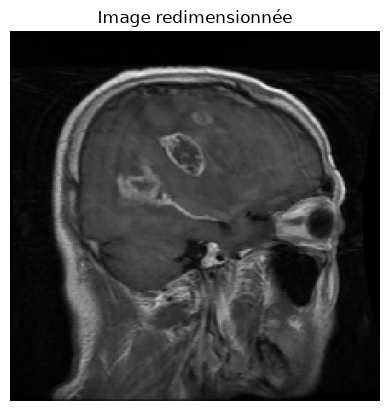

In [32]:
# Définir la taille souhaitée
IMG_SIZE = (224, 224)

# Charger l'image et modifier sa taille
image = load_img(
    image_path,
    target_size=IMG_SIZE,
    color_mode="rgb"
)

# Afficher la taille de l'image
print("Taille de l'image :", image.size)

# Afficher l'image
plt.imshow(image)
plt.title("Image redimensionnée")
plt.axis("off")
plt.show()

In [33]:
# Convertir l'image en tableau NumPy
image_array = img_to_array(image)

# Afficher la forme du tableau
print("Shape :", image_array.shape)

# Afficher le type des données
print("Type :", image_array.dtype)

# Afficher les valeurs minimales et maximales
print("Pixel minimum :", image_array.min())
print("Pixel maximum :", image_array.max())

Shape : (224, 224, 3)
Type : float32
Pixel minimum : 0.0
Pixel maximum : 253.0


In [34]:
# Convertir les valeurs en nombres décimaux
image_array = image_array.astype("float32")

# Normaliser les pixels
image_normalized = image_array / 255.0

# Vérifier les nouvelles valeurs
print("Minimum après normalisation :", image_normalized.min())
print("Maximum après normalisation :", image_normalized.max())

# Vérifier la forme
print("Shape :", image_normalized.shape)

Minimum après normalisation : 0.0
Maximum après normalisation : 0.99215686
Shape : (224, 224, 3)


In [35]:
def preprocess_image(image_path):
    # Charger et redimensionner l'image
    image = load_img(
        image_path,
        target_size=(224, 224),
        color_mode="rgb"
    )

    # Convertir l'image en tableau numérique
    image_array = img_to_array(image)

    # Normaliser les pixels entre 0 et 1
    image_array = image_array / 255.0

    # Retourner l'image prétraitée
    return image_array

In [36]:
# Prétraiter une image
processed_image = preprocess_image(image_path)

# Afficher les informations
print("Shape :", processed_image.shape)
print("Type :", processed_image.dtype)
print("Minimum :", processed_image.min())
print("Maximum :", processed_image.max())

Shape : (224, 224, 3)
Type : float32
Minimum : 0.0
Maximum : 0.99215686


In [37]:
# Ajouter une dimension pour représenter un lot d'images
image_batch = tf.expand_dims(processed_image, axis=0)

# Afficher la nouvelle forme
print("Shape du batch :", image_batch.shape)

Shape du batch : (1, 224, 224, 3)


In [38]:
from pathlib import Path
import shutil
import tensorflow as tf
from tensorflow.keras.utils import image_dataset_from_directory

In [39]:
SPLIT_DIR = PROJECT_ROOT / "Data" / "classification" / "split"

TRAIN_DIR = SPLIT_DIR / "train"
VAL_DIR = SPLIT_DIR / "validation"
TEST_DIR = SPLIT_DIR / "test"

# Créer les dossiers principaux
for folder in [TRAIN_DIR, VAL_DIR, TEST_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Dossiers créés :", SPLIT_DIR)

Dossiers créés : c:\Users\ajbba\Desktop\YOUCODE-IA\Diagnostic_tumeurs\Data\classification\split


In [40]:
for folder in [TRAIN_DIR, VAL_DIR, TEST_DIR]:
    print(f"\nDossier : {folder}")

    if folder.exists():
        images = [
            path for path in folder.rglob("*")
            if path.is_file()
            and path.suffix.lower() in {
                ".jpg", ".jpeg", ".png", ".bmp", ".gif"
            }
        ]

        print("Nombre d'images :", len(images))
    else:
        print("Le dossier n'existe pas.")


Dossier : c:\Users\ajbba\Desktop\YOUCODE-IA\Diagnostic_tumeurs\Data\classification\split\train
Nombre d'images : 5600

Dossier : c:\Users\ajbba\Desktop\YOUCODE-IA\Diagnostic_tumeurs\Data\classification\split\validation
Nombre d'images : 1053

Dossier : c:\Users\ajbba\Desktop\YOUCODE-IA\Diagnostic_tumeurs\Data\classification\split\test
Nombre d'images : 1054


In [41]:
import shutil
from pathlib import Path

# Choisir les données d'entraînement
if "train_final_df" in globals() and len(train_final_df) > 0:
    training_df = train_final_df
else:
    training_df = train_df

# Associer chaque DataFrame à son dossier
datasets_to_copy = [
    (training_df, TRAIN_DIR),
    (val_df, VAL_DIR),
    (test_df, TEST_DIR)
]

# Copier les images
for dataframe, destination_dir in datasets_to_copy:

    for _, row in dataframe.iterrows():

        source_path = Path(row["image_path"])
        class_name = row["class"]

        # Vérifier que l'image source existe
        if not source_path.is_file():
            print("Image introuvable :", source_path)
            continue

        # Créer le dossier de la classe
        class_dir = destination_dir / class_name
        class_dir.mkdir(parents=True, exist_ok=True)

        # Construire le chemin de destination
        destination_path = class_dir / source_path.name

        # Copier l'image si elle n'existe pas déjà
        if not destination_path.exists():
            shutil.copy2(source_path, destination_path)

print("Copie terminée.")

Copie terminée.


In [42]:
from tensorflow.keras.utils import image_dataset_from_directory

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

train_dataset = image_dataset_from_directory(
    TRAIN_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=True,
    seed=42
)

Found 5600 files belonging to 4 classes.


In [43]:
val_dataset = image_dataset_from_directory(
    VAL_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

test_dataset = image_dataset_from_directory(
    TEST_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

Found 1053 files belonging to 4 classes.
Found 1054 files belonging to 4 classes.


In [44]:
print("Classes :", train_dataset.class_names)

print("Nombre de classes :", len(train_dataset.class_names))

Classes : ['glioma', 'meningioma', 'notumor', 'pituitary']
Nombre de classes : 4


In [45]:
# Récupérer un batch d'images
for images, labels in train_dataset.take(1):

    print("Shape des images :", images.shape)
    print("Shape des labels :", labels.shape)

    print("Type des images :", images.dtype)
    print("Exemples de labels :", labels[:10].numpy())

Shape des images : (32, 224, 224, 3)
Shape des labels : (32,)
Type des images : <dtype: 'float32'>
Exemples de labels : [0 2 3 1 3 2 1 1 0 2]


In [46]:
import tensorflow as tf

print("Version de TensorFlow :", tf.__version__)
print("Version de Keras :", tf.keras.__version__)

Version de TensorFlow : 2.21.0
Version de Keras : 3.15.1


In [47]:
import pkg_resources
import tensorflow as tf
import tensorflow_hub as hub
import keras

print("pkg_resources : OK")
print("TensorFlow :", tf.__version__)
print("TensorFlow Hub :", hub.__version__)
print("Keras :", keras.__version__)

C:\Users\ajbba\AppData\Local\Temp\ipykernel_5720\2439863809.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources



pkg_resources : OK
TensorFlow : 2.21.0
TensorFlow Hub : 0.16.1
Keras : 3.15.1


In [48]:
GOOGLENET_URL = (
    "https://tfhub.dev/google/imagenet/inception_v1/feature_vector/4"
)

print("Modèle choisi :", GOOGLENET_URL)

Modèle choisi : https://tfhub.dev/google/imagenet/inception_v1/feature_vector/4


In [49]:
googlenet_module = hub.load(GOOGLENET_URL)

print("GoogLeNet chargé avec succès.")

GoogLeNet chargé avec succès.


In [50]:
# Créer un batch fictif de deux images
images_test = tf.random.uniform(
    shape=(2, 224, 224, 3),
    minval=0,
    maxval=1,
    dtype=tf.float32
)

# Extraire les caractéristiques
features_test = googlenet_module(images_test)

# Afficher les informations
print("Shape des images :", images_test.shape)
print("Shape des caractéristiques :", features_test.shape)

Shape des images : (2, 224, 224, 3)
Shape des caractéristiques : (2, 1024)


In [51]:
class GoogLeNetFeatureExtractor(keras.layers.Layer):

    def __init__(self, module, **kwargs):
        super().__init__(trainable=False, **kwargs)
        self.module = module

    def call(self, inputs):
        return self.module(inputs)

In [52]:
NUM_CLASSES = 4

class_names = [
    "glioma",
    "meningioma",
    "notumor",
    "pituitary"
]

print("Nombre de classes :", NUM_CLASSES)
print("Classes :", class_names)

Nombre de classes : 4
Classes : ['glioma', 'meningioma', 'notumor', 'pituitary']


In [53]:
# Définir l'entrée du modèle
inputs = keras.Input(shape=(224, 224, 3))

# Préparer les pixels entre 0 et 1
normalized_images = keras.layers.Rescaling(1.0 / 255)(inputs)

# Extraire les caractéristiques avec GoogLeNet
feature_extractor = GoogLeNetFeatureExtractor(
    googlenet_module
)

features = feature_extractor(normalized_images)

# Ajouter la nouvelle couche de classification
outputs = keras.layers.Dense(
    NUM_CLASSES,
    activation="softmax"
)(features)

# Créer le modèle complet
model = keras.Model(
    inputs=inputs,
    outputs=outputs,
    name="BrainScan_GoogLeNet"
)

In [54]:
model.summary()

Model: "BrainScan_GoogLeNet"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ goog_le_net_feature_extractor   │ (None, 1024)           │             0 │
│ (GoogLeNetFeatureExtractor)     │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │         4,100 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,100 (16.02 KB)

 Trainable params: 4,100 (16.02 KB)

 Non-trainable params: 0 (0.00 B)

In [55]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)

In [56]:
print("Classes Train :", train_dataset.class_names)
print("Classes Validation :", val_dataset.class_names)
print("Classes Test :", test_dataset.class_names)

Classes Train : ['glioma', 'meningioma', 'notumor', 'pituitary']
Classes Validation : ['glioma', 'meningioma', 'notumor', 'pituitary']
Classes Test : ['glioma', 'meningioma', 'notumor', 'pituitary']


In [57]:
for images, labels in train_dataset.take(1):

    print("Shape des images :", images.shape)
    print("Shape des labels :", labels.shape)

    print("Minimum des pixels :", tf.reduce_min(images).numpy())
    print("Maximum des pixels :", tf.reduce_max(images).numpy())

Shape des images : (32, 224, 224, 3)
Shape des labels : (32,)
Minimum des pixels : 0.0
Maximum des pixels : 255.0


In [58]:
history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=10
)

Epoch 1/10


c:\Users\ajbba\Desktop\YOUCODE-IA\Diagnostic_tumeurs\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


175/175 ━━━━━━━━━━━━━━━━━━━━ 128s 678ms/step - accuracy: 0.7296 - loss: 0.7298 - val_accuracy: 0.8091 - val_loss: 0.5350
Epoch 2/10
175/175 ━━━━━━━━━━━━━━━━━━━━ 118s 675ms/step - accuracy: 0.8413 - loss: 0.4542 - val_accuracy: 0.8452 - val_loss: 0.4266
Epoch 3/10
175/175 ━━━━━━━━━━━━━━━━━━━━ 81s 462ms/step - accuracy: 0.8627 - loss: 0.3847 - val_accuracy: 0.8651 - val_loss: 0.3821
Epoch 4/10
175/175 ━━━━━━━━━━━━━━━━━━━━ 65s 373ms/step - accuracy: 0.8793 - loss: 0.3433 - val_accuracy: 0.8708 - val_loss: 0.3586
Epoch 5/10
175/175 ━━━━━━━━━━━━━━━━━━━━ 49s 279ms/step - accuracy: 0.8909 - loss: 0.3118 - val_accuracy: 0.8879 - val_loss: 0.3305
Epoch 6/10
175/175 ━━━━━━━━━━━━━━━━━━━━ 67s 380ms/step - accuracy: 0.9023 - loss: 0.2885 - val_accuracy: 0.8832 - val_loss: 0.3208
Epoch 7/10
175/175 ━━━━━━━━━━━━━━━━━━━━ 66s 377ms/step - accuracy: 0.9089 - loss: 0.2738 - val_accuracy: 0.8841 - val_loss: 0.3205
Epoch 8/10
175/175 ━━━━━━━━━━━━━━━━━━━━ 60s 340ms/step - accuracy: 0.9139 - loss: 0.2580 - v

In [59]:
# 1. Définir le learning rate
LEARNING_RATE = 0.001

# 2. Définir l'optimiseur
OPTIMIZER = keras.optimizers.Adam(
    learning_rate=LEARNING_RATE
)

# 3. Définir la fonction de perte
LOSS_FUNCTION = keras.losses.SparseCategoricalCrossentropy()

# 4. Compiler le modèle
model.compile(
    optimizer=OPTIMIZER,
    loss=LOSS_FUNCTION,
    metrics=["accuracy"]
)

print("Learning Rate :", LEARNING_RATE)
print("Optimizer : Adam")
print("Loss Function : SparseCategoricalCrossentropy")

Learning Rate : 0.001
Optimizer : Adam
Loss Function : SparseCategoricalCrossentropy


In [60]:
# 1. Définir le learning rate
LEARNING_RATE = 0.001

# 2. Définir l'optimiseur
OPTIMIZER = keras.optimizers.Adam(
    learning_rate=LEARNING_RATE
)

# 3. Définir la fonction de perte
LOSS_FUNCTION = keras.losses.SparseCategoricalCrossentropy()

# 4. Compiler le modèle
model.compile(
    optimizer=OPTIMIZER,
    loss=LOSS_FUNCTION,
    metrics=["accuracy"]
)

print("Learning Rate :", LEARNING_RATE)
print("Optimizer : Adam")
print("Loss Function : SparseCategoricalCrossentropy")

Learning Rate : 0.001
Optimizer : Adam
Loss Function : SparseCategoricalCrossentropy


In [61]:
hyperparameters = {
    "Learning Rate": 0.001,
    "Optimizer": "Adam",
    "Loss Function": "SparseCategoricalCrossentropy",
    "Metric": "Accuracy",
    "Batch Size": 32,
    "Number of Epochs": 10
}

for parameter, value in hyperparameters.items():
    print(f"{parameter} : {value}")

Learning Rate : 0.001
Optimizer : Adam
Loss Function : SparseCategoricalCrossentropy
Metric : Accuracy
Batch Size : 32
Number of Epochs : 10


In [62]:
history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=10
)

Epoch 1/10
175/175 ━━━━━━━━━━━━━━━━━━━━ 69s 382ms/step - accuracy: 0.9252 - loss: 0.2255 - val_accuracy: 0.9022 - val_loss: 0.2678
Epoch 2/10
175/175 ━━━━━━━━━━━━━━━━━━━━ 56s 319ms/step - accuracy: 0.9277 - loss: 0.2158 - val_accuracy: 0.9022 - val_loss: 0.2614
Epoch 3/10
175/175 ━━━━━━━━━━━━━━━━━━━━ 39s 223ms/step - accuracy: 0.9334 - loss: 0.2048 - val_accuracy: 0.9088 - val_loss: 0.2511
Epoch 4/10
175/175 ━━━━━━━━━━━━━━━━━━━━ 51s 290ms/step - accuracy: 0.9345 - loss: 0.2028 - val_accuracy: 0.9136 - val_loss: 0.2494
Epoch 5/10
175/175 ━━━━━━━━━━━━━━━━━━━━ 97s 377ms/step - accuracy: 0.9350 - loss: 0.1930 - val_accuracy: 0.9174 - val_loss: 0.2416
Epoch 6/10
175/175 ━━━━━━━━━━━━━━━━━━━━ 63s 360ms/step - accuracy: 0.9418 - loss: 0.1853 - val_accuracy: 0.9117 - val_loss: 0.2415
Epoch 7/10
175/175 ━━━━━━━━━━━━━━━━━━━━ 65s 371ms/step - accuracy: 0.9393 - loss: 0.1790 - val_accuracy: 0.9117 - val_loss: 0.2366
Epoch 8/10
175/175 ━━━━━━━━━━━━━━━━━━━━ 67s 382ms/step - accuracy: 0.9438 - loss: 0

In [63]:
import pandas as pd

results = pd.DataFrame(history.history)

results.index = results.index + 1
results.index.name = "Epoch"

display(results)

,accuracy,loss,val_accuracy,val_loss
Epoch,,,,
1,0.925179,0.225501,0.902184,0.267758
2,0.927679,0.215832,0.902184,0.261374
3,0.933393,0.204775,0.908832,0.251078
4,0.934464,0.202775,0.913580,0.249448
5,0.935000,0.193030,0.917379,0.241639
6,0.941786,0.185269,0.911681,0.241495
7,0.939286,0.179012,0.911681,0.236643
8,0.943750,0.172801,0.918329,0.236542
9,0.948929,0.168057,0.916429,0.237674


In [64]:
# Évaluer le modèle sur les données de test

test_loss, test_accuracy = model.evaluate(
    test_dataset,
    verbose=1
)

print("Test Loss :", round(test_loss, 4))
print("Test Accuracy :", round(test_accuracy * 100, 2), "%")

33/33 ━━━━━━━━━━━━━━━━━━━━ 11s 321ms/step - accuracy: 0.9231 - loss: 0.2159
Test Loss : 0.2159
Test Accuracy : 92.31 %
